# Les pénuries de carburant se propagent-elles comme une épidémie ?
### La crise d'octobre 2022 dans les stations-service françaises

Auteurs : Sarah LIABES, Adam Trabelsi

## Sommaire

- Introduction
- I. Données
  - A. Ruptures de carburant par station
  - B. Raffineries, dépôts et dates de grève
  - C. Sources de croisement (chiffres officiels, INSEE, contours)
  - D. Contrôles qualité et export
- II. Dynamique de la crise
- III. Choc commun ou contagion locale ?
  - A. H1 : diffusion depuis les raffineries et dépôts en grève
  - B. H2 : report des automobilistes sur les stations voisines
- IV. Comparaison avec une vraie épidémie : le COVID-19
- Conclusion et limites

## Introduction

**Contexte.** 

**Problématique.** Pendant la crise d'octobre 2022, les ruptures en stations-service s'expliquent-elles par un **choc logistique commun** (raffineries et dépôts en grève) ou par une **contagion locale**, les automobilistes se reportant sur les stations voisines ?

**Hypothèses.**
- **H1 — choc commun :** les ruptures se concentrent autour des sites en grève et les stations d'une même zone tombent en même temps.
- **H2 — contagion par report :** une station a plus de chances de tomber en rupture lorsque ses voisines le sont déjà, à approvisionnement comparable.

**Démarche.** 

### Configuration

Le code est rangé dans le package `src/penuries/`. Les cellules ci-dessous l'importent ; les données sont téléchargées depuis leurs sources officielles.

In [1]:
import sys

sys.path.append("src")

import pandas as pd

from penuries import collecte, nettoyage, indicateurs, visualisation

Matplotlib is building the font cache; this may take a moment.


## I. Données

### A. Ruptures de carburant par station

_Source : flux annuel 2022 du site prix-carburants.gouv.fr (données ouvertes du ministère de l'Économie)._

Le flux annuel 2022 recense, pour chaque station-service, ses prix et ses ruptures (carburant, date de début, date de fin si elle est connue). Nous le téléchargeons directement depuis la source officielle, puis nous en extrayons deux tables :
- `df_stations` : une ligne par station (coordonnées, code postal, autoroute ou route, nombre de mises à jour de prix sur la période) ;
- `df_ruptures` : une ligne par épisode de rupture.



In [2]:
chemin_xml = collecte.telecharger_flux_annuel(2022)

df_stations = collecte.lire_stations(chemin_xml)
df_ruptures = collecte.lire_ruptures(chemin_xml)

print(f"{len(df_stations):,} stations, dont {(df_stations['nb_maj_periode'] > 0).sum():,} actives entre septembre et novembre 2022")
print(f"{len(df_ruptures):,} épisodes de rupture au total")
df_ruptures.head()

13,645 stations, dont 9,563 actives entre septembre et novembre 2022
195,032 épisodes de rupture au total


,id_station,latitude,longitude,code_postal,type_route,carburant,debut,fin
0,1000001,4620100,519800,01000,R,GPLc,2017-09-16 09:50:23,NaT
1,1000001,4620100,519800,01000,R,E10,2018-12-13 09:49:49,NaT
2,1000001,4620100,519800,01000,R,E85,2017-09-16 09:50:23,NaT
3,1000001,4620100,519800,01000,R,SP98,2022-10-21 07:51:17,2022-10-21 07:52:49
4,1000001,4620100,519800,01000,R,SP95,2022-10-11 08:31:05,2022-10-11 17:10:56


In [3]:
df_ruptures["debut"].dt.to_period("M").value_counts().sort_index().loc["2022-06":"2022-12"]

debut
2022-06     1654
2022-07     2927
2022-08     2461
2022-09    24528
2022-10    73716
2022-11    36292
2022-12    16000
Freq: M, Name: count, dtype: int64

Par exemple, les ruptures commencées en octobre 2022 sont environ 30 fois plus nombreuses qu'en août, ce qui confirme l'ampleur de la crise. Le fichier contient aussi des ruptures très anciennes sans date de fin (carburants que la station ne vend plus) : nous les traitons dans la partie D.

#### Nettoyage

Nous ne gardons que ce qui sert à répondre à la question :

- **Les stations actives de métropole :** celles qui ont déclaré au moins un prix entre septembre et novembre 2022, avec des coordonnées valides. Le département est déduit du code postal (Corse : 2A pour les codes inférieurs à 20200, 2B au-delà) ; l'outre-mer est exclu.
- **Les ruptures commencées entre le 1er septembre et le 30 novembre 2022.**
- **Les quatre carburants principaux** (gazole, SP95, SP95-E10, SP98) : c'est la définition qu'utilisait le ministère pour compter les stations « en difficulté », ce qui rend nos chiffres comparables aux siens.
- **Les ruptures d'au moins 1 heure et d'au plus 30 jours, avec une date de fin connue.** En dessous d'une heure, il s'agit plutôt d'erreurs de déclaration ; au-delà de 30 jours, ou sans fin connue au 31 décembre, la station a probablement cessé de vendre ce carburant.

In [4]:
df_stations = nettoyage.nettoyer_stations(df_stations)
df_ruptures_periode = nettoyage.nettoyer_ruptures(df_ruptures, df_stations)

print(f"{len(df_stations):,} stations actives dans {df_stations['departement'].nunique()} départements")
print(f"{len(df_ruptures_periode):,} ruptures des carburants principaux entre septembre et novembre 2022")
print(f"Part avec une date de fin connue : {df_ruptures_periode['fin_connue'].mean():.1%}")
df_ruptures_periode["duree_heures"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])

9,563 stations actives dans 96 départements
122,506 ruptures des carburants principaux entre septembre et novembre 2022
Part avec une date de fin connue : 92.9%


count    113778.000000
mean        526.589074
std        5369.389942
min           0.000000
5%            1.184958
25%          14.508889
50%          31.371111
75%          79.936944
95%         328.372681
max      155143.188333
Name: duree_heures, dtype: float64

In [5]:
df_ruptures_propres = nettoyage.filtrer_durees(df_ruptures_periode)

part_ecartee = 1 - len(df_ruptures_propres) / len(df_ruptures_periode)
print(f"{len(df_ruptures_propres):,} ruptures conservées ({part_ecartee:.1%} écartées par les filtres de durée)")
df_ruptures_propres["carburant"].value_counts()

106,527 ruptures conservées (13.0% écartées par les filtres de durée)


carburant
Gazole    35143
E10       31523
SP98      29002
SP95      10859
Name: count, dtype: int64

Sur les 9 563 stations actives de métropole (96 départements), nous retenons 106 325 ruptures des carburants principaux entre septembre et novembre 2022. Les filtres écartent environ 6 % des ruptures : moins de 5 % durent moins d'une heure, 1,3 % n'ont pas de date de fin connue au 31 décembre, et moins de 1 % dépassent 30 jours. Ces seuils éliminent donc les anomalies sans toucher au cœur des données.

La durée médiane d'une rupture est de 30 heures : dans la moitié des cas, une station est réapprovisionnée en un peu plus d'une journée. La distribution est cependant très étalée : un quart des ruptures dépasse 3 jours et 10 % dépassent une semaine. Ces ruptures longues pourraient concerner les stations dépendant des sites restés en grève le plus longtemps : nous le testerons dans la partie III.

Le gazole est le carburant le plus souvent en rupture, devant le SP95-E10 et le SP98. Le SP95 apparaît moins souvent, probablement parce que moins de stations le distribuent depuis la généralisation du SP95-E10 : il faudra raisonner en proportion de stations concernées, et non en nombre brut de ruptures.

### B. Raffineries, dépôts et dates de grève

_Table construite à la main (`data/manuel/`), une source citée par ligne._

#### Inventaire et calendrier des sites pétroliers

Pour caractériser le **choc d'approvisionnement commun** (H1), nous avons constitué une table manuelle recensant sept raffineries ou dépôts concernés par les grèves de 2022. Elle indique, pour chaque site, son type, sa localisation, ses dates de début et de fin de grève et une source documentaire. Cette table est versionnée dans `data/manuel/raffineries_depots.csv` ; les dates de grève sont une approximation du calendrier effectif des perturbations logistiques.

In [6]:
from pathlib import Path

fichier_sites = Path("data/manuel/raffineries_depots.csv")
if not fichier_sites.exists():
    raise FileNotFoundError("Fichier des sites introuvable : data/manuel/raffineries_depots.csv")

sites_h1 = pd.read_csv(fichier_sites, dtype={"departement": str}, encoding="utf-8-sig")
colonnes_sites = {"site", "type", "departement", "debut_greve", "fin_greve", "latitude", "longitude"}
assert colonnes_sites.issubset(sites_h1.columns), "Colonnes manquantes dans raffineries_depots.csv"
for col in ["debut_greve", "fin_greve"]:
    sites_h1[col] = pd.to_datetime(sites_h1[col], errors="raise")
for col in ["latitude", "longitude"]:
    sites_h1[col] = pd.to_numeric(sites_h1[col], errors="raise")

print("Sites pétroliers recensés :", len(sites_h1))
colonnes_affichees = [c for c in ["site", "type", "departement", "debut_greve", "fin_greve", "source"] if c in sites_h1]
display(sites_h1[colonnes_affichees])

Sites pétroliers recensés : 7


,site,type,departement,debut_greve,fin_greve,source
0,Port-Jerome,raffinerie,76,2022-09-20,2022-10-14,https://www.spglobal.com/energy/en/news-resear...
1,Fos-sur-Mer,raffinerie,13,2022-09-21,2022-10-13,https://www.lefigaro.fr/conjoncture/en-direct-...
2,Gonfreville,raffinerie,76,2022-09-27,2022-10-31,https://www.spglobal.com/energy/en/news-resear...
3,Donges,raffinerie,44,2022-10-12,2022-10-19,https://www.ladepeche.fr/2022/10/19/penurie-de...
4,La Mede,bioraffinerie,13,2022-09-27,2022-10-19,https://www.lemonde.fr/economie/article/2022/1...
5,Flandres,depot,59,2022-09-27,2022-10-19,https://www.lemonde.fr/economie/article/2022/1...
6,Feyzin,raffinerie,69,2022-09-27,2022-11-08,https://www.lemonde.fr/economie/article/2022/1...


### C. Sources de croisement

_Chiffres officiels quotidiens du ministère de la Transition énergétique, population INSEE par département, contours des départements._

#### Géographie des stations et données de recoupement

Nous avons préparé les **contours départementaux** (GeoJSON France) et un fichier de **population INSEE 2022** pour les éventuelles normalisations, puis vérifié la correspondance entre les codes de département des stations et ceux du fond de carte. Le module `src/penuries/geographie.py` rassemble les procédures de préparation ; la vérification détaillée des coordonnées figure également dans `verification_stations.ipynb`.

Les codes départementaux sont conservés en **texte** afin de ne pas perdre les zéros initiaux (`01`) ni les codes de la Corse (`2A`, `2B`). Une carte n'est pas une preuve de bonne affectation : les stations proches des frontières départementales exigent une vérification particulière.

In [7]:
# Vérifications élémentaires sur la table commune de Sarah
stations_geo_h1 = df_stations[["id_station", "departement", "latitude", "longitude"]].copy()
stations_geo_h1["id_station"] = stations_geo_h1["id_station"].astype(str)
stations_geo_h1["departement"] = stations_geo_h1["departement"].astype(str).str.zfill(2)
stations_geo_h1[["latitude", "longitude"]] = stations_geo_h1[["latitude", "longitude"]].astype(float)

print("Stations distinctes :", stations_geo_h1["id_station"].nunique())
print("Départements distincts :", stations_geo_h1["departement"].nunique())
print("Coordonnées manquantes :", stations_geo_h1[["latitude", "longitude"]].isna().any(axis=1).sum())
print("Identifiants de station dupliqués :", stations_geo_h1["id_station"].duplicated().sum())

# Tables facultatives de recoupement (sans dépendance pour H1).
pop_path = Path("data/traite/populations_2022.csv")
ministere_path = Path("data/manuel/chiffres_ministere.csv")
print("Population INSEE disponible localement :", pop_path.exists())
print("Chiffres du ministère disponibles localement :", ministere_path.exists())

Stations distinctes : 9563
Départements distincts : 96
Coordonnées manquantes : 0
Identifiants de station dupliqués : 0
Population INSEE disponible localement : True
Chiffres du ministère disponibles localement : True


### D. Contrôles qualité et export


#### Audit géographique complémentaire

Sur la version des données examinée lors de la préparation, nous avons contrôlé la cohérence **station → département** par jointure spatiale. Un premier croisement avec des contours détaillés a fait ressortir **24 observations à examiner** (absence d'appariement ou différence avec le département déclaré), sur **9 563 stations**. Ce sont des *signalements de contrôle*, pas nécessairement 24 erreurs : une station proche d'une limite, une géométrie simplifiée ou une différence de codage peut suffire à expliquer un écart. Nous ne modifions pas automatiquement les départements déclarés.

**Traçabilité.** Le notebook de vérification (`verification_stations.ipynb`) garde les contrôles et les résultats exploratoires. Le présent notebook se fonde sur les tables **nettoyées par le pipeline commun**, déjà construites en partie I.A.

#### Construction de l'indicateur

Nous construisons un **panel station × jour** : chaque jour du 1er septembre au 30 novembre 2022, à 13 h, nous notons si chaque station a au moins une rupture en cours. Nous en tirons deux indicateurs inspirés de l'épidémiologie :
- la **prévalence** : la part de stations en rupture ce jour-là ;
- l'**incidence** : le nombre de stations qui passent en rupture ce jour-là, alors qu'elles ne l'étaient pas la veille.

In [8]:
panel = indicateurs.panel_station_jour(df_ruptures_propres, df_stations)
panel = indicateurs.ajouter_nouvelles_ruptures(panel)
df_prev = indicateurs.prevalence(panel)
df_prev.head()

,jour,pct_en_rupture,nouvelles_ruptures
0,2022-09-01,0.982955,94
1,2022-09-02,1.934539,138
2,2022-09-03,3.388058,209
3,2022-09-04,5.542194,213
4,2022-09-05,7.267594,306


#### Validation de l'indicateur

Nous définissons une station comme en rupture un jour donné si, à 13 h, elle déclare au moins une rupture en cours sur l'un des quatre carburants principaux. L'heure de 13 h est celle des relevés publiés par le ministère pendant la crise.

Avant d'analyser la crise, nous vérifions que cet indicateur est fiable de trois façons :
1. **Son niveau en temps normal** (septembre, avant les grèves) doit être bas.
2. **La date du pic** doit correspondre à celle des sources officielles.
3. **Son niveau pendant la crise** doit être comparable aux chiffres publiés : ceux du ministère de la Transition énergétique, et ceux de l'analyse indépendante de l'AFP sur les mêmes données publiques.

In [9]:
niveau_normal = df_prev.set_index("jour").loc["2022-09-05":"2022-09-25", "pct_en_rupture"]
pic_prevalence = df_prev.loc[df_prev["pct_en_rupture"].idxmax()]
pic_incidence = df_prev.loc[df_prev["nouvelles_ruptures"].idxmax()]

print(f"Niveau normal (5-25 septembre) : {niveau_normal.min():.1f} % à {niveau_normal.max():.1f} %, moyenne {niveau_normal.mean():.1f} %")
print(f"Pic de prévalence : {pic_prevalence['pct_en_rupture']:.1f} % le {pic_prevalence['jour']:%d/%m}")
print(f"Pic d'incidence : {pic_incidence['nouvelles_ruptures']} nouvelles stations en rupture le {pic_incidence['jour']:%d/%m}")

Niveau normal (5-25 septembre) : 4.4 % à 7.6 %, moyenne 5.9 %
Pic de prévalence : 49.6 % le 16/10
Pic d'incidence : 857 nouvelles stations en rupture le 10/10


In [10]:
"""df_officiels = pd.read_csv("data/manuel/chiffres_officiels.csv", parse_dates=["date"])

comparaison = df_officiels.merge(
    df_prev[["jour", "pct_en_rupture"]], left_on="date", right_on="jour", how="left"
)
comparaison[["date", "source", "indicateur", "valeur", "pct_en_rupture"]].round(1)"""

'df_officiels = pd.read_csv("data/manuel/chiffres_officiels.csv", parse_dates=["date"])\n\ncomparaison = df_officiels.merge(\n    df_prev[["jour", "pct_en_rupture"]], left_on="date", right_on="jour", how="left"\n)\ncomparaison[["date", "source", "indicateur", "valeur", "pct_en_rupture"]].round(1)'

En temps normal, 4 à 8 % des stations déclarent une rupture, avec de petits pics les dimanches et lundis, faute de livraison le week-end. Pendant la crise, l'indicateur atteint 49,6 % le 16 octobre, soit environ huit fois ce niveau. Le pic des nouvelles ruptures (857 stations le 10 octobre) coïncide avec le pic des chiffres officiels.

Nos pourcentages sont toutefois 6 à 20 points au-dessus de ceux du ministère, et décroissent plus lentement. Deux raisons l'expliquent :
- **La définition diffère.** Selon l'AFP, le ministère ne comptait que les stations déclarant une « rupture » et excluait celles marquées « non distribué ». Cette distinction n'existe pas dans les données publiques, qui mélangent les deux.
- **Les fins de rupture sont parfois déclarées en retard.** Une rupture reste ouverte dans le fichier tant que la station ne met pas à jour ses données. Cela gonfle la fin de la courbe et retarde le pic de prévalence.

L'analyse de l'AFP, menée sur les mêmes données publiques, trouve des niveaux proches des nôtres (environ 47 % de stations manquant d'essence ou de gazole le 17 octobre, 31 % le 20 octobre). Nos chiffres sont un peu au-dessus, car une station compte chez nous dès qu'il lui manque un seul des quatre carburants.

Conséquence pour la suite : notre indicateur surestime probablement le niveau absolu de la pénurie, mais il en restitue bien la chronologie. Nous l'utilisons donc surtout pour comparer des dates, des départements et des stations entre eux, ce qui est exactement ce que demande notre question.

## II. Dynamique de la crise


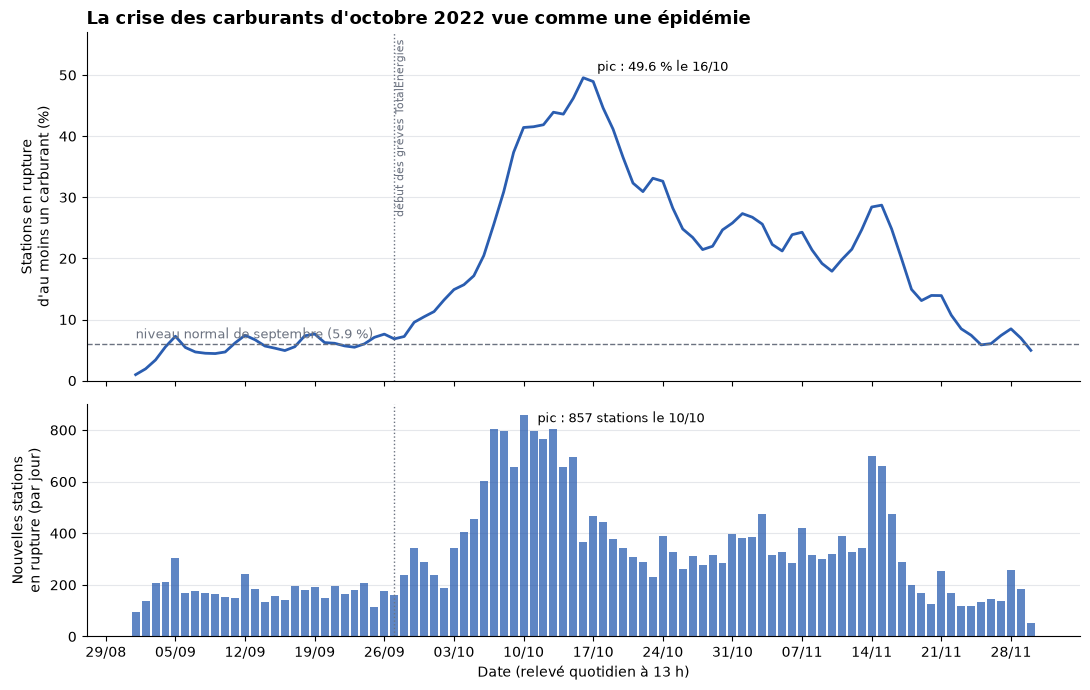

In [11]:
fig = visualisation.courbe_epidemique(
    df_prev,
    niveau_normal=niveau_normal.mean(),
    dates_cles={"2022-09-27": "début des grèves TotalEnergies"},
)

**Lecture.** La crise suit une dynamique proche d'une épidémie, en trois temps.

- - **Avant la crise (septembre).** Entre 4 et 8 % des stations déclarent une rupture chaque jour (5,9 % en moyenne), et environ 150 à 200 stations y entrent chaque jour : c'est le bruit de fond des ruptures ordinaires, avec de légères hausses les dimanches et lundis, faute de livraison le week-end. La courbe part de presque 0 % le 1er septembre et ne rejoint ce niveau que vers le 5 : c'est un artefact des données. Le fichier source enregistre beaucoup moins de ruptures avant septembre (2 461 ruptures commencées en août, contre environ 180 par jour début septembre), si bien que les ruptures en cours au début du mois sont sous-comptées. Nous ne tenons donc pas compte des premiers jours de septembre dans l'analyse : le niveau normal est calculé du 5 au 25 septembre.
- **Croissance rapide (fin septembre – 9 octobre).** La hausse devient visible quelques jours après le début des grèves (27 septembre), puis s'accélère nettement à partir du 3 octobre : la part de stations en rupture passe d'environ 15 % à 41 % en moins d'une semaine. Les nouvelles ruptures sont alors quatre à cinq fois plus nombreuses qu'en temps normal, avec un pic de **857 stations le 10 octobre**, date qui coïncide avec le pic des chiffres officiels.
- **Pic puis décrue lente (10 octobre – fin novembre).** La part de stations en rupture reste au-dessus de 40 % du 9 au 16 octobre et culmine à **49,6 % le 16 octobre**, six jours après le pic des nouvelles ruptures : comme dans une épidémie, le nombre de « malades » continue de croître tant que les nouvelles contaminations dépassent les guérisons. Elle redescend ensuite vers 30 % en une semaine, mais se maintient entre 20 et 30 % jusqu'à mi-novembre, avec un rebond à environ 29 % le 14 novembre. Le niveau normal n'est retrouvé que fin novembre.

La crise est donc asymétrique : une dizaine de jours pour monter, plus de six semaines pour se résorber. Une partie de cette lenteur peut venir des fins de rupture déclarées en retard (partie I.D), mais le maintien d'un nombre élevé de nouvelles ruptures fin octobre (300 à 400 par jour, environ le double du niveau normal) montre que la tension sur l'approvisionnement a réellement duré.

Le rebond de mi-novembre est inattendu, car il survient bien après le pic de la crise : nous vérifions dans la partie III s'il est localisé dans quelques départements.

Ce graphique décrit la chronologie de la crise, mais ne permet pas à lui seul de trancher entre choc commun et contagion : la partie III examine où et dans quel ordre les stations tombent en rupture.

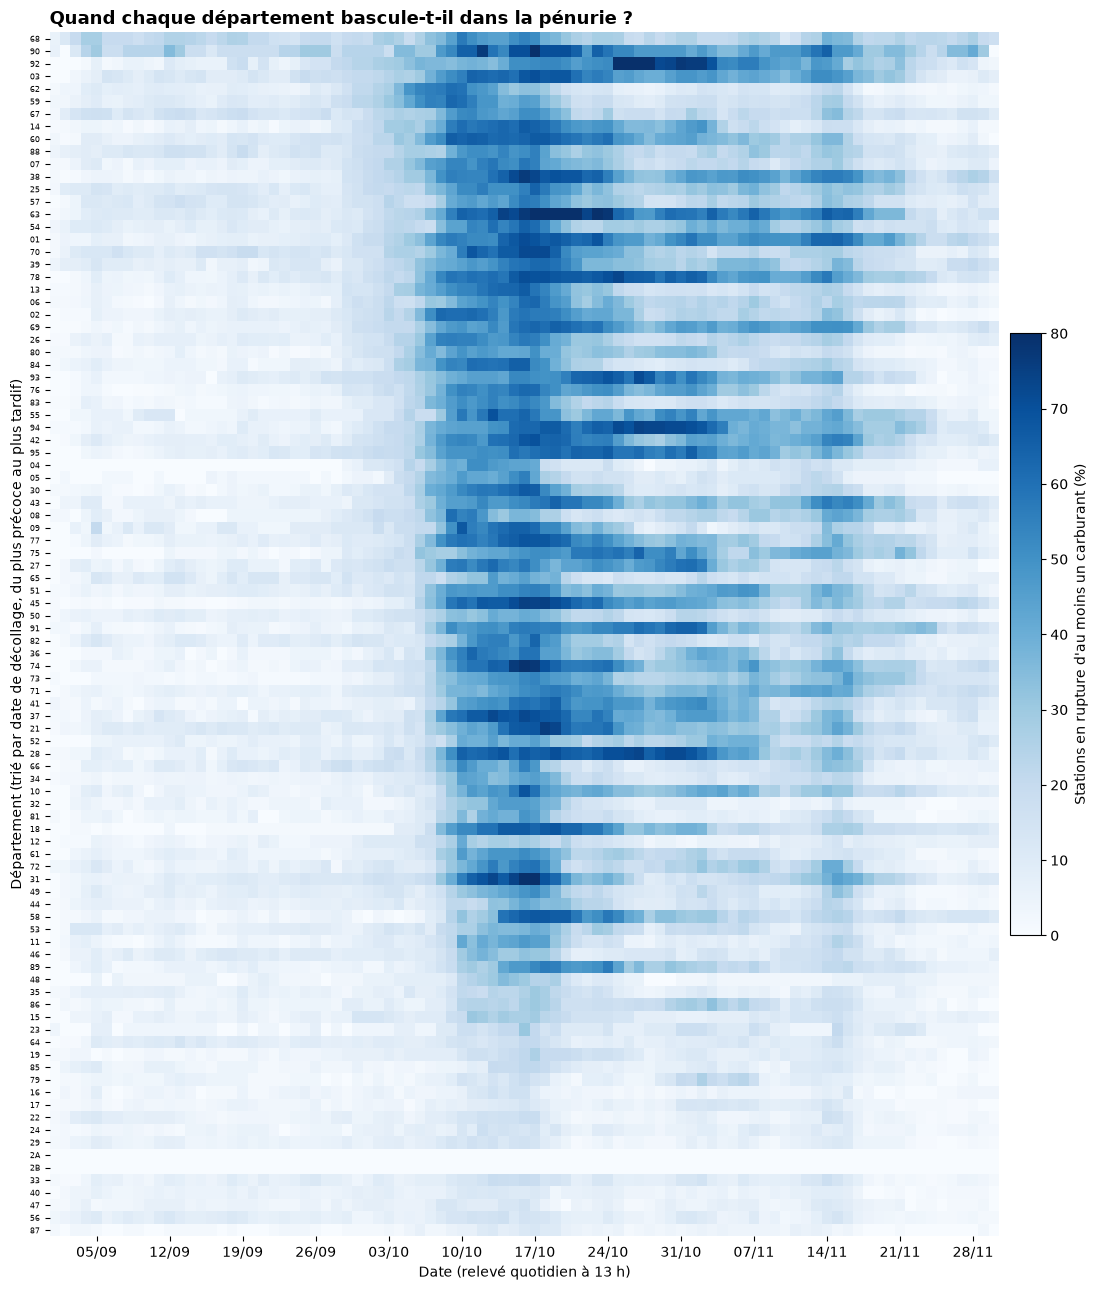

In [12]:
df_prev_dep = indicateurs.prevalence(panel, par="departement")
dates_decollage = indicateurs.date_decollage(df_prev_dep)

fig = visualisation.carte_chaleur_departements(df_prev_dep, dates_decollage)

Chaque ligne est un département, trié du plus précoce au plus tardif selon sa date de décollage (premier jour, à partir du 26 septembre, où au moins 20 % de ses stations sont en rupture, soit plus de trois fois le niveau normal).

- **Un basculement presque simultané.** La grande majorité des départements franchissent le seuil dans la même semaine, entre le 7 et le 12 octobre, ce qui dessine un front presque vertical. La moitié des départements touchés décollent entre le [X] et le [X]. La pénurie ne se diffuse donc pas progressivement d'une région à l'autre, comme le ferait une épidémie : elle frappe l'essentiel du territoire en quelques jours, ce qui évoque plutôt un **choc commun** (H1).
- **Un démarrage plus précoce dans le Nord.** Le Nord (59) et le Pas-de-Calais (62) sont fortement touchés dès les 3-6 octobre, quelques jours avant le reste du pays. Nous confrontons cette avance à la localisation des sites en grève dans la partie III.
- **Une intensité et une durée très inégales.** L'Île-de-France, le Centre et l'axe Lyon–Clermont-Ferrand restent fortement touchés jusqu'à début novembre, tandis que le Sud-Est se rétablit dès le 20 octobre. L'Ouest et le Sud-Ouest (Bretagne, Nouvelle-Aquitaine) sont presque épargnés : [X] départements n'atteignent jamais le seuil. La Corse, approvisionnée par voie maritime, n'est pas touchée.
- **Le rebond de mi-novembre** apparaît comme une fine bande verticale qui touche de nombreux départements le même jour : il relève d'une cause nationale, et non d'une propagation locale.

Limite : le Haut-Rhin (68) et le Territoire de Belfort (90) apparaissent en tête du classement, mais leur niveau est déjà élevé en septembre (environ 20 à 25 %) : ils franchissent le seuil sans véritable crise. Un seuil défini relativement au niveau de septembre de chaque département corrigerait ce biais.

Ce graphique suggère donc un déclenchement largement simultané, compatible avec un choc logistique commun, mais une géographie très marquée de l'intensité et de la durée. Reste à savoir si cette géographie s'explique par la proximité des sites en grève (H1, partie III.A), et si, à l'intérieur d'un département, les ruptures se transmettent de station en station (H2, partie III.B).

## III. Choc commun ou contagion locale ?

### A. H1 — Distance aux raffineries et dépôts en grève

**Question.** Les ruptures de carburant sont-elles compatibles avec un **choc logistique commun** ? Si les perturbations de l'approvisionnement partent des sites en grève, les territoires situés à proximité pourraient être touchés plus tôt. Deux outils descriptifs sont mobilisés : **G3**, des cartes de prévalence par département, et **G4**, la relation entre la distance à un site en grève et la date de « décollage » des pénuries.

**Unité statistique.** Les stations servent à mesurer la prévalence et les distances ; le test de G4 porte sur les **départements**. Une corrélation départementale ne doit pas être interprétée comme une causalité au niveau des stations.

#### 1. Distances aux sites pétroliers : construction et contrôle

Nous utilisons les coordonnées des **9 563 stations** et celles des **sept sites** de notre table manuelle. Les distances sont calculées en kilomètres par la formule de Haversine, qui approxime la distance sur la surface terrestre. Le module `src/penuries/distances.py` contient la fonction réutilisable et ses tests élémentaires (dont un calcul Paris–Marseille).

Ici, nous recalculons la distance au **plus proche des sept sites recensés**, indépendamment des dates de grève. Cette première distance décrit la géographie des sites ; le test G4 utilisera, lui, les **sites signalés en grève à la date considérée**.

In [13]:
from penuries.distances import distance_km
import numpy as np

assert stations_geo_h1["id_station"].is_unique, "Une ligne par station est requise."
assert not sites_h1[["latitude", "longitude"]].isna().any().any()

resultats_distances_h1 = []
for station in stations_geo_h1.itertuples(index=False):
    comparaisons = [
        (distance_km(station.latitude, station.longitude, s.latitude, s.longitude), s.site)
        for s in sites_h1.itertuples(index=False)
    ]
    dist, nom_site = min(comparaisons, key=lambda element: element[0])
    resultats_distances_h1.append({
        "id_station": station.id_station,
        "departement": station.departement,
        "site_proche": nom_site,
        "distance_km": float(dist)
    })

df_distances_h1 = pd.DataFrame(resultats_distances_h1)
print("Stations géolocalisées :", len(df_distances_h1))
print("Distances manquantes :", df_distances_h1["distance_km"].isna().sum())
display(df_distances_h1["distance_km"].describe(percentiles=[.25, .50, .75, .90]).round(2).to_frame("km"))
display(df_distances_h1.head())

Stations géolocalisées : 9563
Distances manquantes : 0


,km
count,9563.00
mean,169.80
std,104.62
min,0.44
25%,88.68
50%,149.43
75%,241.20
90%,327.55
max,470.22


,id_station,departement,site_proche,distance_km
0,1000001,01,Feyzin,64.896393
1,1000004,01,Feyzin,65.242931
2,1000007,01,Feyzin,68.486942
3,1000009,01,Feyzin,65.451711
4,1000012,01,Feyzin,64.961975


**Lecture.** La distance mesure une **proximité géographique**, et non le réseau réel d'approvisionnement : la station la plus proche d'une raffinerie ne reçoit pas nécessairement son carburant de celle-ci. Les dépôts et raffineries ne sont pas tous de même nature. Cette variable sert donc à tester un faisceau d'indices pour H1, pas à identifier les circuits logistiques.

#### 2. G3 — Cartes départementales de diffusion des pénuries

Nous reprenons **exactement la mesure de prévalence du notebook commun** : une station est en rupture lorsqu'au moins un des quatre carburants principaux manque **à 13 h**, chaque jour. Pour chaque département, nous divisons le nombre de stations en rupture par le nombre de stations observées.

Les quatre dates retenues sont **19 septembre, 1er octobre, 10 octobre et 20 octobre 2022**. La couleur des départements mesure le pourcentage en rupture, et les croix indiquent les sites dont le calendrier mentionne une grève à la date considérée. Les quatre cartes partagent la même échelle, pour rendre les comparaisons possibles.

In [14]:
# Construire la prévalence départementale à partir du panel déjà produit par Sarah.
# L'affectation départementale vient de df_stations pour éviter toute ambiguïté.
ids_deps_h1 = stations_geo_h1[["id_station", "departement"]]
etat_h1 = panel[["id_station", "jour", "en_rupture"]].copy()
etat_h1["id_station"] = etat_h1["id_station"].astype(str)
etat_h1["jour"] = pd.to_datetime(etat_h1["jour"]).dt.normalize()
assert not etat_h1.duplicated(["id_station", "jour"]).any(), "Doublons dans le panel station-jour"

etat_h1 = etat_h1.merge(ids_deps_h1, on="id_station", how="left", validate="many_to_one")
assert etat_h1["departement"].notna().all(), "Stations sans département après jointure"
etat_h1["en_rupture"] = etat_h1["en_rupture"].fillna(False).astype(bool)

taux_dep_h1 = (
    etat_h1.groupby(["jour", "departement"], observed=True)["en_rupture"]
    .mean().mul(100).rename("taux_rupture_pct").reset_index()
)

# Contrôle : 96 départements et le calendrier d'observation commun.
print("Départements dans le panel :", taux_dep_h1["departement"].nunique())
print("Dates dans le panel :", taux_dep_h1["jour"].nunique())
dates_cartes_h1 = pd.to_datetime(["2022-09-19", "2022-10-01", "2022-10-10", "2022-10-20"])
for jour in dates_cartes_h1:
    sous_table = taux_dep_h1.loc[taux_dep_h1["jour"] == jour]
    print(jour.strftime("%d/%m/%Y"), "— départements au-dessus de 10 % :", int((sous_table["taux_rupture_pct"] > 10).sum()))

Départements dans le panel : 96
Dates dans le panel : 91
19/09/2022 — départements au-dessus de 10 % : 20
01/10/2022 — départements au-dessus de 10 % : 49
10/10/2022 — départements au-dessus de 10 % : 90
20/10/2022 — départements au-dessus de 10 % : 84


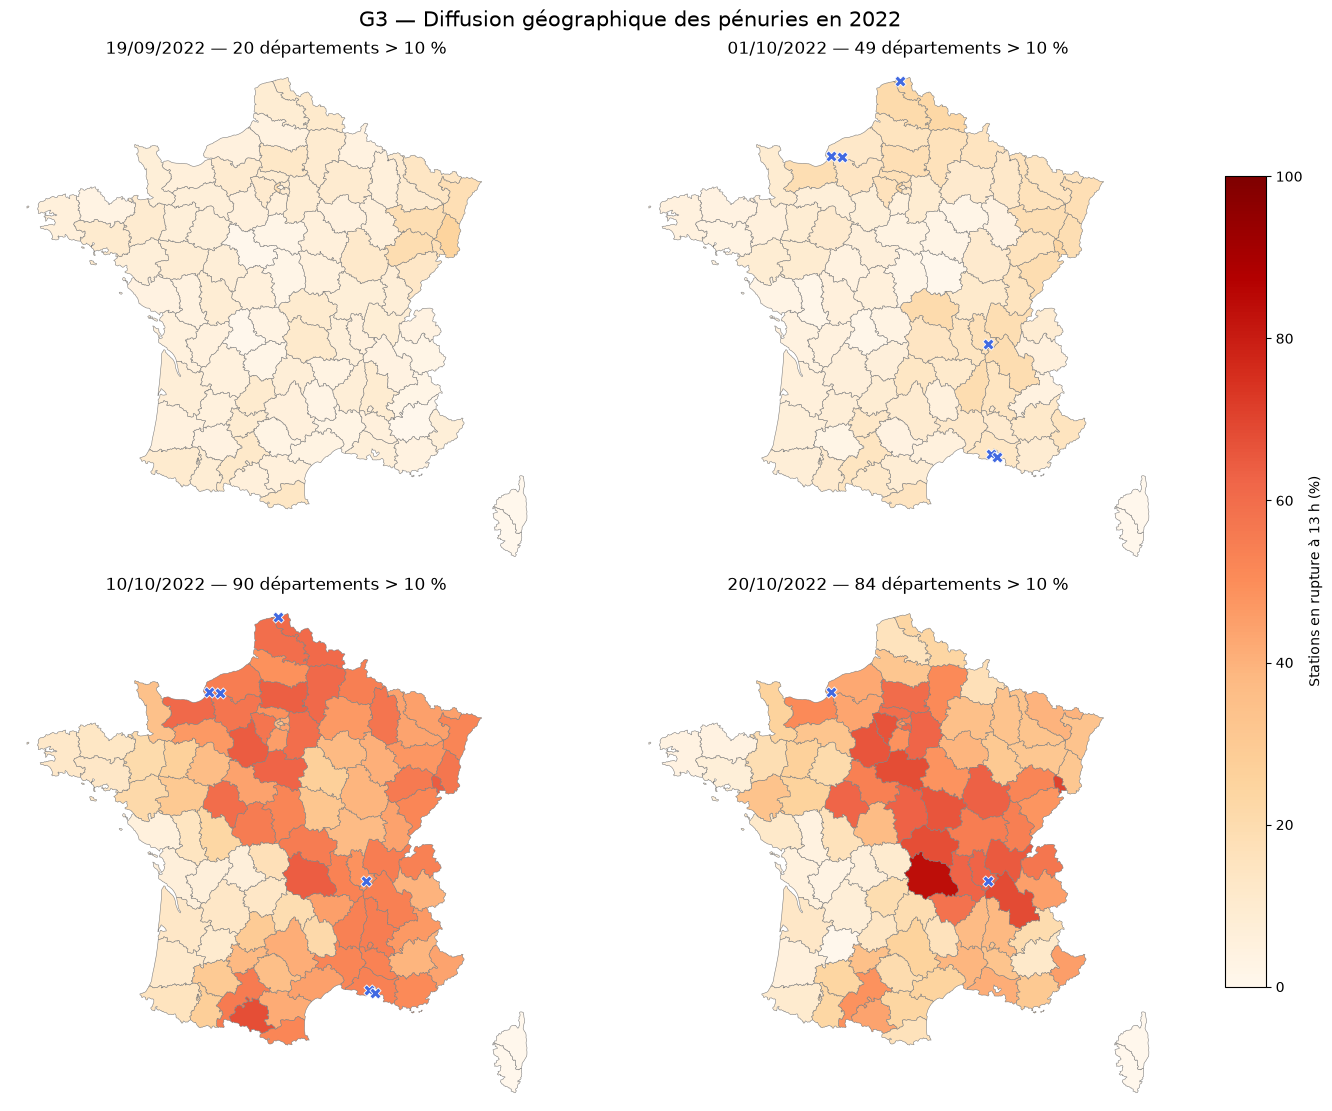

In [15]:
import json
import urllib.request
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

url_geo_h1 = (
    "https://raw.githubusercontent.com/gregoiredavid/france-geojson/"
    "master/departements-version-simplifiee.geojson"
)
with urllib.request.urlopen(url_geo_h1, timeout=30) as reponse:
    geo_h1 = json.load(reponse)

contours_h1 = gpd.GeoDataFrame.from_features(geo_h1["features"], crs="EPSG:4326")
contours_h1["code"] = contours_h1["code"].astype(str)
contours_h1 = contours_h1.loc[contours_h1["code"].isin(stations_geo_h1["departement"].unique()), ["code", "geometry"]]

fig, axes = plt.subplots(2, 2, figsize=(14, 11), constrained_layout=True)
nuancier = "OrRd"
echelle = Normalize(vmin=0, vmax=100)
for ax, jour in zip(axes.flat, dates_cartes_h1):
    valeurs = taux_dep_h1.loc[taux_dep_h1["jour"] == jour, ["departement", "taux_rupture_pct"]]
    carte = contours_h1.merge(valeurs, left_on="code", right_on="departement", how="left", validate="one_to_one")
    carte.plot(column="taux_rupture_pct", ax=ax, cmap=nuancier, vmin=0, vmax=100,
               edgecolor="grey", linewidth=0.4,
               missing_kwds={"color": "lightgrey"})
    sites_actifs = sites_h1.loc[
        (sites_h1["debut_greve"] <= jour) & (sites_h1["fin_greve"] >= jour)
    ]
    ax.scatter(sites_actifs["longitude"], sites_actifs["latitude"],
               marker="X", s=65, color="royalblue", edgecolors="white", linewidths=.6, zorder=5)
    n_dep = int((valeurs["taux_rupture_pct"] > 10).sum())
    ax.set_title(f"{jour:%d/%m/%Y} — {n_dep} départements > 10 %")
    ax.set_xlim(-5.6, 10.0)
    ax.set_ylim(41.2, 51.4)
    ax.set_axis_off()

fig.colorbar(ScalarMappable(norm=echelle, cmap=nuancier), ax=axes.ravel().tolist(),
             shrink=.78, label="Stations en rupture à 13 h (%)")
fig.suptitle("G3 — Diffusion géographique des pénuries en 2022", fontsize=15)

Path("resultats").mkdir(exist_ok=True)
fig.savefig("resultats/G3_cartes_diffusion_13h.png", dpi=220, bbox_inches="tight")
plt.show()

**Interprétation de G3.** Les cartes décrivent l'extension territoriale de la crise et mettent en regard les départements en difficulté et les sites en grève. Elles doivent être lues **avec les taux calculés ci-dessus** : des différences d'heure ou d'échantillon peuvent modifier légèrement les comptes publiés dans les explorations précédentes. La coïncidence spatiale ne démontre pas à elle seule que la grève d'un site est à l'origine des ruptures d'un département.

Le **fond de carte** provient du dépôt public `gregoiredavid/france-geojson` ; les points bleus sont issus de notre table manuelle sourcée.

#### 3. G4 — Distance et date de décollage départementale

Pour rendre le test **cohérent avec la partie II de Sarah**, nous prenons pour analyse principale la même définition de *date de décollage* : **premier jour à partir du 26 septembre 2022 où au moins 20 % des stations du département sont en rupture à 13 h**.

Nous représentons chaque département par la moyenne des coordonnées de ses stations (un **centre moyen**, pas un barycentre économique) puis calculons la distance à vol d'oiseau au **site recensé en grève le plus proche à sa date de décollage**. Le coefficient de Spearman mesure l'association monotone entre distance et retard de décollage, sans supposer une relation linéaire.

**Précaution de sélection.** Un département déjà au-dessus de 20 % le 26 septembre a une date de premier franchissement possiblement antérieure : nous le considérons comme *censuré à gauche* et le retirons du calcul de corrélation. Les départements ne franchissant pas le seuil ou sans site actif à leur date de décollage sont également exclus du test, et leur nombre est indiqué.

In [16]:
from scipy.stats import spearmanr

seuil_h1 = 20.0
debut_observation_h1 = pd.Timestamp("2022-09-26")
franchissements_h1 = taux_dep_h1.loc[
    (taux_dep_h1["jour"] >= debut_observation_h1)
    & (taux_dep_h1["taux_rupture_pct"] >= seuil_h1)
]
premieres_dates_h1 = (
    franchissements_h1.groupby("departement", observed=True)["jour"]
    .min().rename("date_decollage").reset_index()
)
centres_h1 = (
    stations_geo_h1.groupby("departement", as_index=False)[["latitude", "longitude"]]
    .mean()
)
g4_h1 = centres_h1.merge(premieres_dates_h1, on="departement", how="left", validate="one_to_one")
g4_h1["censure_entree"] = g4_h1["date_decollage"].eq(debut_observation_h1)

def proximite_site_actif_h1(ligne):
    date = ligne["date_decollage"]
    if pd.isna(date):
        return pd.Series({"site_actif_plus_proche": None, "distance_site_actif_km": np.nan})
    actifs = sites_h1.loc[(sites_h1["debut_greve"] <= date) & (sites_h1["fin_greve"] >= date)]
    if actifs.empty:
        return pd.Series({"site_actif_plus_proche": None, "distance_site_actif_km": np.nan})
    dist, site = min(
        (distance_km(ligne["latitude"], ligne["longitude"], s.latitude, s.longitude), s.site)
        for s in actifs.itertuples(index=False)
    )
    return pd.Series({"site_actif_plus_proche": site, "distance_site_actif_km": dist})

g4_h1 = pd.concat([g4_h1, g4_h1.apply(proximite_site_actif_h1, axis=1)], axis=1)
g4_h1["jours_depuis_26_sept"] = (g4_h1["date_decollage"] - debut_observation_h1).dt.days
valides_h1 = g4_h1.loc[
    ~g4_h1["censure_entree"]
].dropna(subset=["distance_site_actif_km", "jours_depuis_26_sept"]).copy()

rho_h1, pvalue_h1 = (spearmanr(valides_h1["distance_site_actif_km"],
                                valides_h1["jours_depuis_26_sept"])
                      if len(valides_h1) >= 3 else (np.nan, np.nan))
print("Départements au total :", len(g4_h1))
print("Au-dessus du seuil dès le 26/09 (censurés) :", int(g4_h1["censure_entree"].sum()))
print("N'ayant pas franchi le seuil :", int(g4_h1["date_decollage"].isna().sum()))
print("Sans site actif associé :", int((g4_h1["date_decollage"].notna() & g4_h1["distance_site_actif_km"].isna()).sum()))
print("Départements retenus pour G4 :", len(valides_h1))
print(f"Spearman = {rho_h1:.4f} ; p-value indicative = {pvalue_h1:.3g}")
display(valides_h1[["departement", "date_decollage", "site_actif_plus_proche", "distance_site_actif_km"]].head(10))

Départements au total : 96
Au-dessus du seuil dès le 26/09 (censurés) : 2
N'ayant pas franchi le seuil : 12
Sans site actif associé : 0
Départements retenus pour G4 : 82
Spearman = 0.3921 ; p-value indicative = 0.000269


,departement,date_decollage,site_actif_plus_proche,distance_site_actif_km
0,01,2022-10-03,Feyzin,60.076975
1,02,2022-10-03,Flandres,182.350561
2,03,2022-09-30,Feyzin,152.553332
3,04,2022-10-05,La Mede,108.141102
4,05,2022-10-05,Feyzin,162.049499
5,06,2022-10-03,La Mede,167.326722
6,07,2022-10-02,Feyzin,103.301053
7,08,2022-10-06,Flandres,224.235698
8,09,2022-10-06,Fos-sur-Mer,274.486842
9,10,2022-10-08,Port-Jerome,292.023250


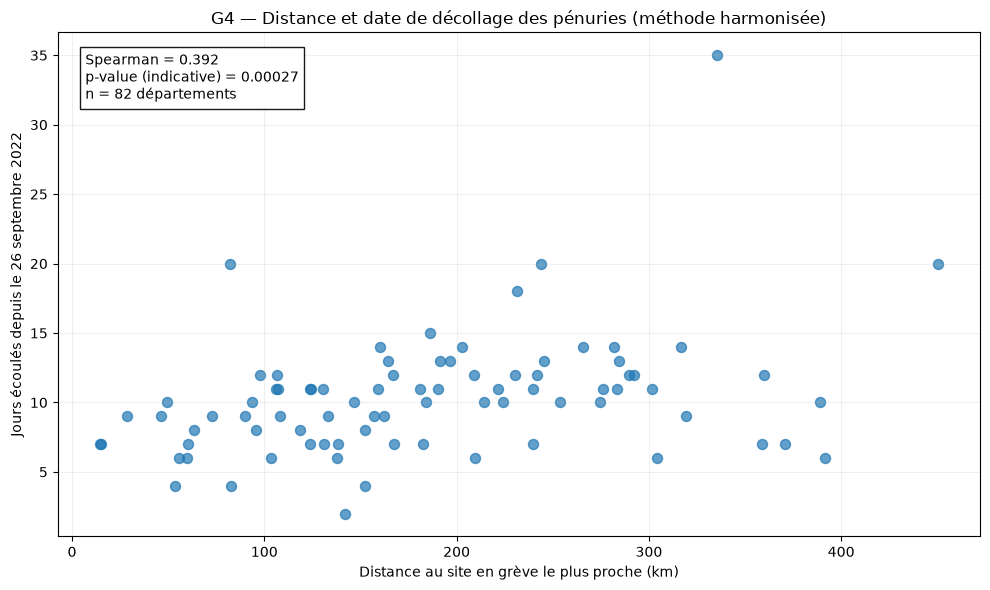

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(valides_h1["distance_site_actif_km"], valides_h1["jours_depuis_26_sept"],
           alpha=.7, s=52)
ax.set_title("G4 — Distance et date de décollage des pénuries (méthode harmonisée)")
ax.set_xlabel("Distance au site en grève le plus proche (km)")
ax.set_ylabel("Jours écoulés depuis le 26 septembre 2022")
ax.text(.03, .96,
        f"Spearman = {rho_h1:.3f}\np-value (indicative) = {pvalue_h1:.2g}\nn = {len(valides_h1)} départements",
        transform=ax.transAxes, va="top", bbox={"facecolor": "white", "alpha": .9})
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig("resultats/G4_distance_decollage_13h_20pct.png", dpi=220, bbox_inches="tight")
g4_h1.to_csv("resultats/G4_departements_13h_20pct.csv", index=False)
plt.show()

#### 4. Mise en perspective avec les résultats exploratoires déjà livrés

Avant l'harmonisation avec le `main.ipynb`, nous avions produit G3 et G4 à partir d'un **autre relevé des ruptures (12 h)** et d'un **seuil de décollage strictement supérieur à 10 %** sur la période septembre–novembre. L'étude initiale de G4 avait conservé **55 départements**, dont la date de premier franchissement était postérieure ou égale au 20 septembre ; elle donnait **ρ de Spearman = +0,539** avec **p = 2,19 × 10⁻⁵**. Les **39 départements** ayant déjà franchi 10 % avant le 20 septembre et les **2 départements** n'ayant jamais franchi ce seuil étaient exclus.

Ces fichiers sont archivés dans `resultats/G3_cartes_diffusion.png`, `resultats/G4_distance_decollage.png` et `resultats/G4_donnees.csv`. **Le résultat +0,539 ne doit pas être présenté comme le coefficient de la version 13 h / 20 % recalculée ci-dessus.** Il s'agit d'une analyse exploratoire de sensibilité, avec une fenêtre et une sélection différentes. Les comptages historiques utilisaient aussi un export SSP Cloud de **106 325 épisodes**, alors que l'exécution fournie du `main.ipynb` affiche **106 527 épisodes après filtrage** ; il faut donc privilégier, pour le rendu final, les résultats recalculés à partir des mêmes données que Sarah.

#### 5. Bilan et limites de H1

Les cartes G3 mettent en évidence la diffusion géographique des pénuries : à 13 h, le nombre de départements présentant plus de 10 % de stations en rupture passe de 20 le 19 septembre à 90 le 10 octobre 2022.

L'analyse G4, réalisée avec un seuil de décollage de 20 %, porte sur 82 départements. Elle révèle une corrélation de Spearman positive et modérée entre la distance aux sites pétroliers en grève et la date de décollage des pénuries (**ρ = 0,3921 ; p-value indicative = 0,000269**).

Ces résultats sont compatibles avec l'hypothèse H1 d'un choc logistique commun : les départements les plus éloignés des sites en grève tendent à être touchés plus tardivement. Ils ne permettent toutefois pas d'établir un lien causal, compte tenu des limites de mesure, de sélection et d'inférence détaillées ci-dessous.

Plusieurs réserves sont essentielles :

- **Mesure des ruptures :** les déclarations peuvent être mises à jour avec retard et un seul carburant manquant suffit à classer une station en rupture ;
- **Distance imparfaite :** la distance à vol d'oiseau, mesurée depuis un centre moyen de stations, ne décrit ni les flux de carburant ni la véritable chaîne logistique ;
- **Calendrier des grèves :** les dates par site sont établies à partir de sources de presse et peuvent ne pas refléter exactement la disponibilité effective des produits ;
- **Sélection des départements :** certains ont déjà franchi le seuil à l'entrée de la période, d'autres ne le franchissent pas ; les exclure peut modifier la corrélation ;
- **Distance définie à la date de décollage :** le groupe des sites « actifs » dépend de la date étudiée, ce qui peut introduire une dépendance mécanique dans le test ;
- **Inférence :** les départements ne sont pas indépendants spatialement. La p-value usuelle du test de Spearman est donc seulement indicative.

**Conclusion partielle.** H1 propose une explication logistique plausible de la synchronisation et de la géographie de la crise. Les analyses restent **descriptives** et ne permettent pas de départager définitivement choc commun et contagion locale : l'hypothèse H2 devra être étudiée dans la section suivante.

**Reproductibilité.** Les données de rupture et de stations sont construites en partie I, les coordonnées et dates des sites figurent dans `data/manuel/raffineries_depots.csv`, les fonctions géographiques sont dans `src/penuries/`, et les figures recalculées sont exportées dans `resultats/`. La cartographie nécessite `geopandas` et l'accès au GeoJSON public lors de la première exécution.

### B. H2 — Contagion locale entre stations

*Section à compléter avec Sarah dans le cadre de la version finale du notebook.

## IV. Comparaison avec une vraie épidémie : le COVID-19

*Section à intégrer par l'équipe à partir des analyses COVID prévues dans la feuille de route.*

## Conclusion et limites générales

*À rédiger collectivement une fois H1, H2 et la comparaison COVID consolidées. La conclusion générale ne doit pas être déduite de H1 seule.*